In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
# Tải dữ liệu Boston Housing từ OpenML
boston = fetch_openml(data_id=531, as_frame=False)

X = boston.data
y = boston.target.astype(float)

print("Kích thước dữ liệu:", X.shape)
print("Kích thước nhãn:", y.shape)

print("5 dòng dữ liệu đầu tiên:")
print(X[:5])

Kích thước dữ liệu: (506, 13)
Kích thước nhãn: (506,)
5 dòng dữ liệu đầu tiên:
[[0.00632 18.0 2.31 '0' 0.538 6.575 65.2 4.09 '1' 296.0 15.3 396.9 4.98]
 [0.02731 0.0 7.07 '0' 0.469 6.421 78.9 4.9671 '2' 242.0 17.8 396.9 9.14]
 [0.02729 0.0 7.07 '0' 0.469 7.185 61.1 4.9671 '2' 242.0 17.8 392.83 4.03]
 [0.03237 0.0 2.18 '0' 0.458 6.998 45.8 6.0622 '3' 222.0 18.7 394.63 2.94]
 [0.06905 0.0 2.18 '0' 0.458 7.147 54.2 6.0622 '3' 222.0 18.7 396.9 5.33]]


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Số lượng dữ liệu huấn luyện:", len(X_train))
print("Số lượng dữ liệu kiểm tra:", len(X_test))

Số lượng dữ liệu huấn luyện: 404
Số lượng dữ liệu kiểm tra: 102


In [ ]:
scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
k_values = [3, 5, 7, 9]

results = []

for k in k_values:

    knn_model = KNeighborsRegressor(n_neighbors=k)

    knn_model.fit(X_train_scaled, y_train)

    y_pred = knn_model.predict(X_test_scaled)

    mse = mean_squared_error(y_test, y_pred)

    r2 = r2_score(y_test, y_pred)

    results.append({
        'K': k,
        'MSE': mse,
        'R2 Score': r2
    })

    print(f"\nK = {k}")
    print(f"MSE: {mse:.4f}")
    print(f"R2 Score: {r2:.4f}")


K = 3
MSE: 20.3819
R2 Score: 0.7221

K = 5
MSE: 21.7122
R2 Score: 0.7039

K = 7
MSE: 23.8135
R2 Score: 0.6753

K = 9
MSE: 26.5110
R2 Score: 0.6385


In [ ]:
results_df = pd.DataFrame(results)

print("\nBẢNG SO SÁNH KẾT QUẢ KNN REGRESSION")
print(results_df)


BẢNG SO SÁNH KẾT QUẢ KNN REGRESSION
   K        MSE  R2 Score
0  3  20.381895  0.722067
1  5  21.712184  0.703927
2  7  23.813485  0.675273
3  9  26.511011  0.638488


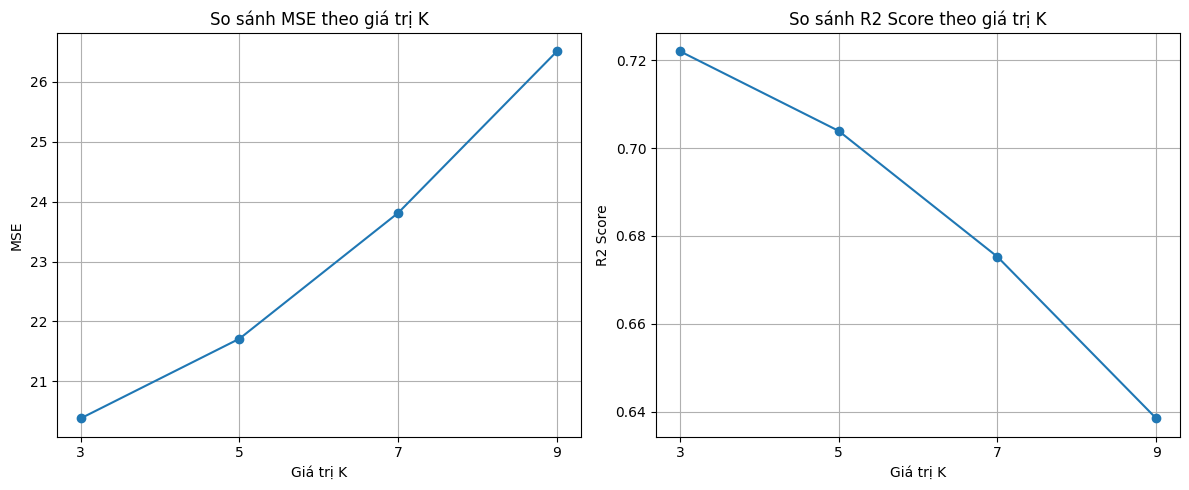

In [ ]:
plt.figure(figsize=(12, 5))

# Biểu đồ MSE
plt.subplot(1, 2, 1)
plt.plot(results_df['K'], results_df['MSE'], marker='o')
plt.xlabel('Giá trị K')
plt.ylabel('MSE')
plt.title('So sánh MSE theo giá trị K')
plt.xticks(k_values)
plt.grid(True)

# Biểu đồ R2 Score
plt.subplot(1, 2, 2)
plt.plot(results_df['K'], results_df['R2 Score'], marker='o')
plt.xlabel('Giá trị K')
plt.ylabel('R2 Score')
plt.title('So sánh R2 Score theo giá trị K')
plt.xticks(k_values)
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
best_mse = results_df.loc[results_df['MSE'].idxmin()]

best_r2 = results_df.loc[results_df['R2 Score'].idxmax()]

print("K tốt nhất theo MSE:")
print(best_mse)

print("\nK tốt nhất theo R2 Score:")
print(best_r2)

K tốt nhất theo MSE:
K            3.000000
MSE         20.381895
R2 Score     0.722067
Name: 0, dtype: float64

K tốt nhất theo R2 Score:
K            3.000000
MSE         20.381895
R2 Score     0.722067
Name: 0, dtype: float64
